In [1]:
## Importing libraries
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

In [2]:
import warnings 
warnings.filterwarnings('ignore')

In [3]:
# Loading the datasets
df_raw = pd.read_csv("flipkart_laptops.csv")
df = df_raw.copy() 

#### Basic Data Understanding

In [4]:
df.head()

,Brand,Model,Price,Rating,Processor,RAM,ROM
0,Samsung,Samsung Galaxy Book4 Metal Intel Core i5 13th ...,"₹60,990₹82,78926% off","4.420,432 Ratings&2,200 Reviews",Intel Core i5 Processor (13th Gen),16 GB LPDDR4X RAM,512 GB SSD
1,ASUS,ASUS ExpertBook P1 with 1 Yr ADP (i5 14th Gen)...,"₹64,990₹1,20,99046% off","4.41,124 Ratings&131 Reviews",Intel Core 5 Processor,16 GB DDR4 RAM,512 GB SSD
2,DELL,DELL Alienware 15 AMD Ryzen 7 260,"₹1,19,990₹1,62,95726% off",4.56 Ratings&3 Reviews,AMD Ryzen 7 Processor,16 GB DDR5 RAM,512 GB SSD
3,ASUS,ASUS ExpertBook P1 Intel Core 3 100U,"₹46,990₹95,99051% off",4.84 Ratings&1 Reviews,Intel Core 3 Processor,8 GB DDR4 RAM,512 GB SSD
4,Acer,Acer Aspire 14 AMD Ryzen 3 3200U,"₹34,990₹84,99958% off",4.1145 Ratings&25 Reviews,AMD Ryzen 3 Processor,8 GB DDR4 RAM,512 GB SSD


In [5]:
df.tail()

,Brand,Model,Price,Rating,Processor,RAM,ROM
495,DELL,DELL Inspiron 5440 (2025) Intel Core i3 13th G...,"₹67,840₹74,9909% off",4.378 Ratings&5 Reviews,Intel Core i3 Processor (13th Gen),16 GB DDR5 RAM,512 GB SSD
496,ASUS,ASUS ExpertBook P1 with 1 Yr ADP (i3 14th Gen)...,"₹61,990₹1,09,99043% off",NaN,Intel Core 3 Processor,16 GB DDR5 RAM,512 GB SSD
497,ASUS,ASUS ExpertBook P1 with 1 Yr ADP (i5 14th Gen)...,"₹71,990₹1,44,99050% off",NaN,Intel Core 5 Processor,16 GB DDR5 RAM,512 GB SSD
498,Lenovo,Lenovo IdeaPad Slim 3 Backlit Intel Core i5 13...,"₹78,960₹1,00,00021% off",NaN,Intel Core i5 Processor (13th Gen),16 GB LPDDR5 RAM,512 GB SSD
499,Lenovo,Lenovo IdeaPad Slim 5 (Gen 11) Next-Gen AI PC ...,"₹1,27,299₹2,39,29046% off",NaN,NaN,16 GB DDR5 RAM,512 GB SSD


In [6]:
df.shape

(500, 7)

In [7]:
df.columns

Index(['Brand', 'Model', 'Price', 'Rating', 'Processor', 'RAM', 'ROM'], dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Brand      500 non-null    object
 1   Model      500 non-null    object
 2   Price      500 non-null    object
 3   Rating     403 non-null    object
 4   Processor  496 non-null    object
 5   RAM        500 non-null    object
 6   ROM        485 non-null    object
dtypes: object(7)
memory usage: 27.5+ KB


In [9]:
df.dtypes

Brand        object
Model        object
Price        object
Rating       object
Processor    object
RAM          object
ROM          object
dtype: object

In [10]:
df.describe(include="all")

,Brand,Model,Price,Rating,Processor,RAM,ROM
count,500,500,500,403,496,500,485
unique,11,245,281,231,54,24,5
top,ASUS,ASUS ExpertBook P1 with 1 Yr ADP (i5 14th Gen)...,"₹60,990₹82,78926% off",4.820 Ratings&3 Reviews,Intel Core 5 Processor,16 GB DDR5 RAM,512 GB SSD
freq,196,40,21,22,76,174,430


In [11]:
print(df.isnull().sum())

Brand         0
Model         0
Price         0
Rating       97
Processor     4
RAM           0
ROM          15
dtype: int64


#### Handling Duplicate Values

In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 119


In [13]:
df = df.drop_duplicates().copy()

In [14]:
print("Shape after removing duplicates:", df.shape)
print("Duplicates after cleaning:", df.duplicated().sum())

Shape after removing duplicates: (381, 7)
Duplicates after cleaning: 0


#### Coverting to valid datatypes

In [15]:
df["Price"] = pd.to_numeric(
    df["Price"].str.replace(",", "", regex=False)
    .str.extract(r"₹\s*([\d,]+)")[0],
    errors="coerce"
)

print(df["Price"].head())
print(df["Price"].dtype)

0     60990.0
1     64990.0
2    119990.0
3     46990.0
4     34990.0
Name: Price, dtype: float64
float64


In [16]:
df["Rating"] = pd.to_numeric(
    df["Rating"].str.extract(r"^\s*([0-5](?:\.\d+)?)")[0],
    errors="coerce"
)

print(df["Rating"].head())
print(df["Rating"].dtype)

0    4.4200
1    4.4100
2    4.5600
3    4.8400
4    4.1145
Name: Rating, dtype: float64
float64


#### Handling Missing Values

In [17]:
df.isnull().sum()

Brand         0
Model         0
Price         3
Rating       60
Processor     4
RAM           0
ROM          15
dtype: int64

In [18]:
# As it is not a values that can be randomly guessed replace missing values with Not Available
df["Processor"] = df["Processor"].fillna("Not Available") 
df["ROM"] = df["ROM"].fillna("Not Available")

In [19]:
## Handling Inconsistency in Data
df["Brand"] = df["Brand"].str.strip()
df["Model"] = df["Model"].str.strip()
df["Processor"] = df["Processor"].str.strip()
df["RAM"] = df["RAM"].str.strip()
df["ROM"] = df["ROM"].str.strip()

In [20]:
print(df.dtypes)

Brand         object
Model         object
Price        float64
Rating       float64
Processor     object
RAM           object
ROM           object
dtype: object


In [21]:
df = df.dropna(subset=["Price"]).copy() # As only few price is missing it can be simply deleted rather than replacing it.

print("Shape:", df.shape)
print(df.isnull().sum())

Shape: (378, 7)
Brand         0
Model         0
Price         0
Rating       60
Processor     0
RAM           0
ROM           0
dtype: int64


In [23]:
print("Missing ratings:", df["Rating"].isnull().sum())
print("Available ratings:", df["Rating"].notnull().sum())

Missing ratings: 60
Available ratings: 318


##### Checking Inconsistency

In [24]:
print("Number of unique values:")
df.nunique()

Number of unique values:


Brand         11
Model        243
Price        217
Rating       170
Processor     55
RAM           24
ROM            6
dtype: int64

In [25]:
print(df["Brand"].unique())

['Samsung' 'ASUS' 'DELL' 'Acer' 'Lenovo' 'MOTOROLA' 'HP' 'Apple'
 'Primebook' 'Prittec' 'MSI']


#### Handling Outliers

In [27]:
for col in ["Price", "Rating"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    print(f"\n{col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))


Price
Q1: 54492.25
Q3: 88990.0
IQR: 34497.75
Lower Limit: 2745.625
Upper Limit: 140736.625
Number of Outliers: 24

Rating
Q1: 4.18
Q3: 4.4693
IQR: 0.2892999999999999
Lower Limit: 3.74605
Upper Limit: 4.90325
Number of Outliers: 8


In [28]:
df["Price"].describe()

count       378.000000
mean      77563.568783
std       41956.955345
min       14990.000000
25%       54492.250000
50%       67415.000000
75%       88990.000000
max      349990.000000
Name: Price, dtype: float64

In [29]:
df["Rating"].describe()

count    318.000000
mean       4.344076
std        0.277299
min        3.000000
25%        4.180000
50%        4.345950
75%        4.469300
max        5.000000
Name: Rating, dtype: float64

In [31]:
Q1_price = df["Price"].quantile(0.25)
Q3_price = df["Price"].quantile(0.75)
IQR_price = Q3_price - Q1_price

price_outliers = df[
    (df["Price"] < Q1_price - 1.5 * IQR_price) |
    (df["Price"] > Q3_price + 1.5 * IQR_price)
]

print(price_outliers[["Brand", "Model", "Price"]].sort_values("Price"))


       Brand                                              Model     Price
99      Acer        Acer Nitro 5 Intel Core i5 14th Gen 14450HX  149990.0
403     Acer        Acer Nitro 5 Intel Core i5 14th Gen 14450HX  149990.0
292     DELL  DELL Alienware 16 Aurora (i7 14th Gen) Microso...  154990.0
68        HP             HP Victus AI AMD Ryzen 7 Octa Core 260  156990.0
253     ASUS         ASUS TUF Gaming A16 (2026) AMD Ryzen 7 260  159525.0
92    Lenovo              Lenovo Legion 5 Intel Core i7 13650HX  159990.0
435   Lenovo          Lenovo LOQ 2025 AMD Ryzen 7 Octa Core 250  159990.0
464     DELL                DELL Alienware 15 Intel Core 7 240H  159990.0
224   Lenovo          Lenovo LOQ 2025 AMD Ryzen 7 Octa Core 250  165990.0
62    Lenovo     Lenovo Legion 5 2025 AMD Ryzen 7 Octa Core 260  169990.0
483     DELL                DELL Alienware 15 Intel Core 7 240H  170990.0
162   Lenovo     Lenovo LOQ 2025 Intel Core i7 14th Gen 14700HX  186990.0
13      DELL  DELL Alienware 16 Aurora

##### Price: The upper limit is ₹140,736.63. Laptops above this price may be premium models, not errors.

##### Rating: The IQR limits are 3.746 and 4.903. Ratings outside these limits are statistically unusual, but they can still be valid and in describe the max value for rating is 5 so all values are valid.

##### So, the outliers will not be removed as it can impact the total price analysis

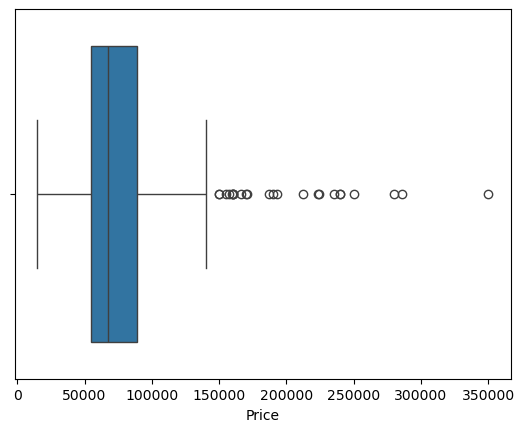

In [32]:
sns.boxplot(x=df["Price"])
plt.show()

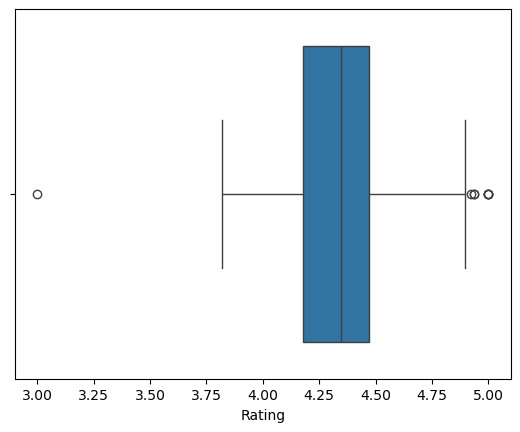

In [33]:
sns.boxplot(x=df["Rating"])
plt.show()

In [34]:
# 15. Check remaining records
print("Original rows:", len(df_raw))
print("Remaining rows:", len(df))

Original rows: 500
Remaining rows: 378


In [64]:
df.to_csv("flipkart_laptops_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")
print("Final shape:", df.shape)

Cleaned dataset saved successfully.
Final shape: (378, 9)


## Descriptive Analysis

In [35]:
print("Total laptops:", len(df))
print("Total brands:", df["Brand"].nunique())

print("\nPrice statistics:")
print(df["Price"].describe())

print("\nRating statistics:")
print(df["Rating"].describe())

Total laptops: 378
Total brands: 11

Price statistics:
count       378.000000
mean      77563.568783
std       41956.955345
min       14990.000000
25%       54492.250000
50%       67415.000000
75%       88990.000000
max      349990.000000
Name: Price, dtype: float64

Rating statistics:
count    318.000000
mean       4.344076
std        0.277299
min        3.000000
25%        4.180000
50%        4.345950
75%        4.469300
max        5.000000
Name: Rating, dtype: float64


### Brand analysis

In [36]:
print(df["Brand"].value_counts())

Brand
ASUS         126
HP            68
Acer          61
Lenovo        57
DELL          23
Samsung       15
MOTOROLA       9
Apple          8
MSI            7
Primebook      2
Prittec        2
Name: count, dtype: int64


In [37]:
brand_counts = df["Brand"].value_counts()

print("Most listed brand:", brand_counts.idxmax())
print("Number of listings:", brand_counts.max())

Most listed brand: ASUS
Number of listings: 126


### Price analysis

In [38]:
print("Average price:", round(df["Price"].mean(), 2))
print("Median price:", df["Price"].median())
print("Minimum price:", df["Price"].min())
print("Maximum price:", df["Price"].max())
print("Standard deviation:", round(df["Price"].std(), 2))

Average price: 77563.57
Median price: 67415.0
Minimum price: 14990.0
Maximum price: 349990.0
Standard deviation: 41956.96


### Compare prices by brand

In [39]:
brand_price = df.groupby("Brand")["Price"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

print(brand_price.sort_values("mean", ascending=False))

           count       mean    median       min       max
Brand                                                    
Apple          8  168142.38  139990.0  139990.0  239900.0
MSI            7   91004.00   99000.0   57999.0  109990.0
DELL          23   90578.17   67840.0   49990.0  189990.0
Lenovo        57   82641.28   71990.0   14990.0  223890.0
ASUS         126   80599.47   71990.0   24990.0  349990.0
Samsung       15   79470.60   60990.0   47990.0  286099.0
HP            68   72286.32   65650.0   16999.0  156990.0
MOTOROLA       9   71767.78   69990.0   64990.0   77990.0
Acer          61   57729.00   50990.0   22299.0  149990.0
Primebook      2   30490.00   30490.0   29990.0   30990.0
Prittec        2   25795.00   25795.0   25795.0   25795.0


### Rating analysis

In [40]:
print("Available ratings:", df["Rating"].count())
print("Missing ratings:", df["Rating"].isnull().sum())
print("Average rating:", round(df["Rating"].mean(), 2))

print("\nAverage rating by brand:")
print(df.groupby("Brand")["Rating"].mean().sort_values(ascending=False))

Available ratings: 318
Missing ratings: 60
Average rating: 4.34

Average rating by brand:
Brand
MOTOROLA     4.498375
MSI          4.489133
Apple        4.471200
Samsung      4.464293
DELL         4.405183
ASUS         4.373442
Primebook    4.320000
Lenovo       4.285147
Acer         4.282876
HP           4.281210
Prittec      4.204500
Name: Rating, dtype: float64


### Processor analysis

In [41]:
print(df["Processor"].value_counts())

Processor
Intel Core 3 Processor                                                        40
Intel Core 5 Processor                                                        33
Intel Core i5 Processor (13th Gen)                                            23
Intel Core i3 Processor (13th Gen)                                            21
Intel Core Ultra 5 Processor                                                  19
AMD Ryzen 3 Quad Core Processor                                               18
AMD Ryzen 5 Hexa Core Processor                                               17
Intel Core Ultra 7 Processor                                                  16
Intel Core i5 Processor (12th Gen)                                            14
AMD Ryzen 5 Quad Core Processor                                               13
AMD Ryzen 7 Octa Core Processor                                               13
AMD Ryzen 3 Processor                                                         11
Intel Celeron Dual

In [42]:
## Compare prices by processor description.
processor_price = df.groupby("Processor")["Price"].agg(
    ["count", "mean", "median"]
).sort_values("mean", ascending=False)

print(processor_price)

                                                    count           mean  \
Processor                                                                  
Intel Core Ultra X7 Processor                           2  294990.000000   
Intel Core Ultra 7 Processor (Series 3)                 1  286099.000000   
AMD Ryzen 9 16 Core Processor                           3  251220.666667   
Apple M1 Pro Processor                                  1  239900.000000   
AMD Ryzen AI Max+ Processor                             1  234990.000000   
Intel Core i7 Processor                                 2  191940.000000   
Intel Core i7 Processor (14th Gen)                      1  186990.000000   
Apple M5 Processor                                      7  157891.285714   
Intel Core 7 Processor                                  6  147656.500000   
Intel Core i5 Processor (14th Gen)                      3  143323.333333   
AMD Ryzen 7 Processor                                   5  125698.800000   
Intel Core i

### RAM analysis

In [43]:
df["RAM_GB"] = pd.to_numeric(
    df["RAM"].str.extract(r"(\d+)\s*GB", expand=False),
    errors="coerce"
)

print(df["RAM_GB"].value_counts().sort_index())

RAM_GB
4      14
8     143
12      2
16    210
24      4
32      4
64      1
Name: count, dtype: int64


In [44]:
## Compare RAM capacity with price.
print(
    df.groupby("RAM_GB")["Price"]
    .agg(["count", "mean", "median"])
    .round(2)
)

        count       mean    median
RAM_GB                            
4          14   28698.71   29273.5
8         143   53965.47   53990.0
12          2   40689.00   40689.0
16        210   91755.14   79519.0
24          4  128817.25  106490.0
32          4  246242.25  237490.0
64          1  349990.00  349990.0


### Storage analysis

In [45]:
df["Storage_GB"] = pd.to_numeric(
    df["ROM"].str.extract(r"(\d+(?:\.\d+)?)\s*GB", expand=False),
    errors="coerce"
)

tb_values = df["ROM"].str.extract(
    r"(\d+(?:\.\d+)?)\s*TB", expand=False
)

df.loc[tb_values.notna(), "Storage_GB"] = (
    pd.to_numeric(tb_values[tb_values.notna()]) * 1024
)

print(df["Storage_GB"].value_counts().sort_index())

Storage_GB
128.0       1
256.0      19
512.0     311
1024.0     31
2048.0      1
Name: count, dtype: int64


In [46]:
## Compare storage capacity with price.
print(
    df.groupby("Storage_GB")["Price"]
    .agg(["count", "mean", "median"])
    .round(2)
)

            count       mean    median
Storage_GB                            
128.0           1   16999.00   16999.0
256.0          19   41331.26   40990.0
512.0         311   73876.70   67994.0
1024.0         31  154250.26  149990.0
2048.0          1  349990.00  349990.0


In [47]:
print(df[["Price", "Rating"]].corr())

           Price    Rating
Price   1.000000  0.273568
Rating  0.273568  1.000000


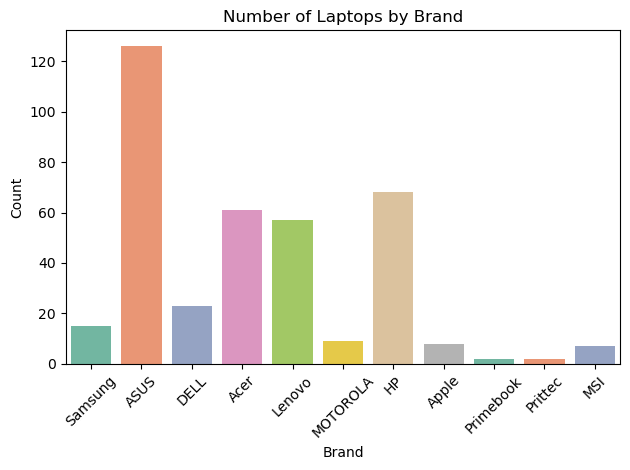

In [50]:
sns.countplot(data=df, x="Brand",palette = "Set2")

plt.title("Number of Laptops by Brand")
plt.xlabel("Brand")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

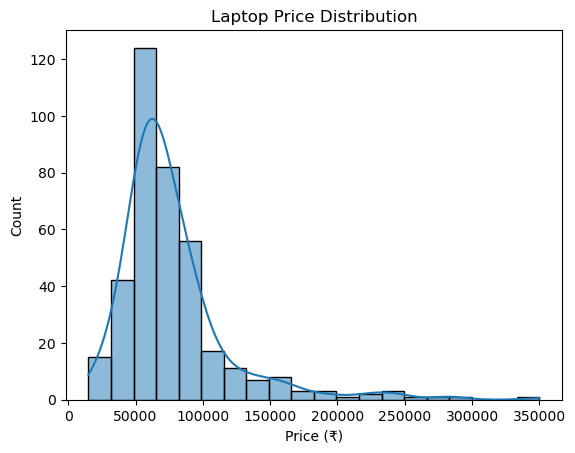

In [53]:
sns.histplot(data=df, x="Price", bins=20, kde=True)

plt.title("Laptop Price Distribution")
plt.xlabel("Price (₹)")
plt.ylabel("Count")
plt.show()

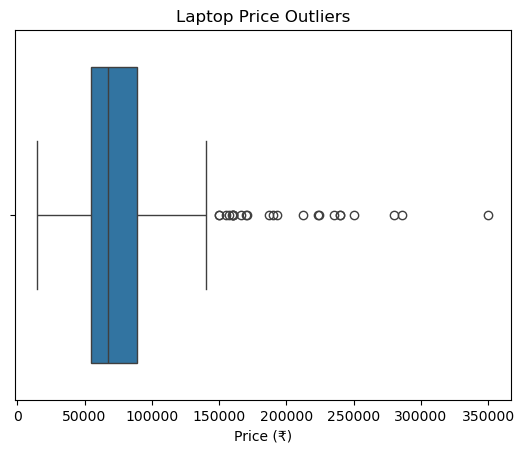

In [54]:
sns.boxplot(data=df, x="Price")

plt.title("Laptop Price Outliers")
plt.xlabel("Price (₹)")
plt.show()

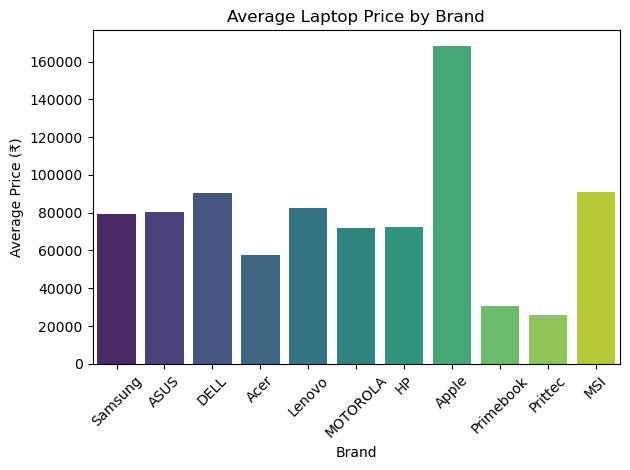

In [58]:
sns.barplot(data=df, x="Brand", y="Price",palette = "viridis" ,errorbar=None)

plt.title("Average Laptop Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

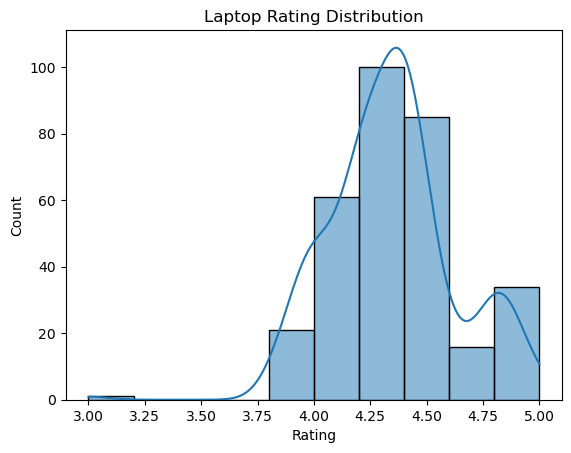

In [59]:
sns.histplot(data=df, x="Rating", bins=10, kde=True)

plt.title("Laptop Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

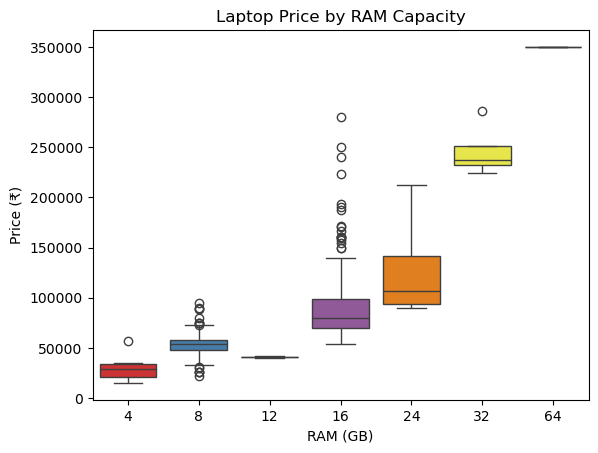

In [61]:
sns.boxplot(data=df, x="RAM_GB", y="Price",palette = "Set1")

plt.title("Laptop Price by RAM Capacity")
plt.xlabel("RAM (GB)")
plt.ylabel("Price (₹)")
plt.show()

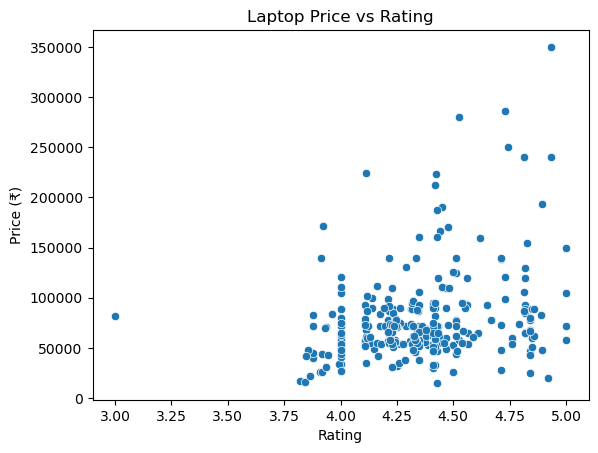

In [62]:
sns.scatterplot(data=df, x="Rating", y="Price")

plt.title("Laptop Price vs Rating")
plt.xlabel("Rating")
plt.ylabel("Price (₹)")
plt.show()

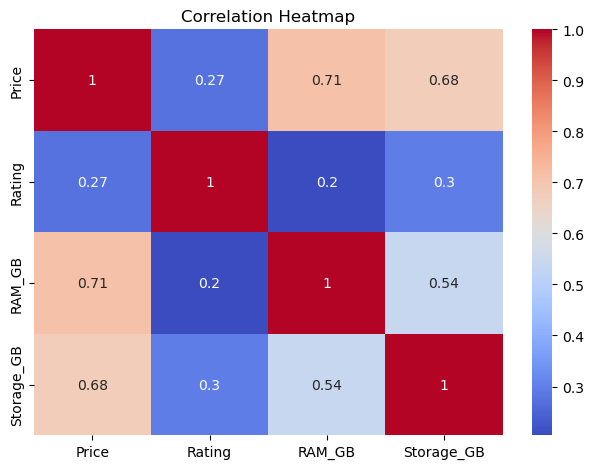

In [63]:
sns.heatmap(
    df[["Price", "Rating", "RAM_GB", "Storage_GB"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Key Business Insights

### 1. Market and brand analysis
- ASUS dominates the dataset with 126 listings, representing approximately 33.3% of all laptop listings.
- HP has 68 listings (18.0%), followed by Acer with 61 (16.1%) and Lenovo with 57 (15.1%).
- The four leading brands account for approximately 82.5% of the dataset.
- Apple has only 8 listings but the highest average price at ₹1,68,142, indicating a premium-priced product range in this sample.
- Acer has a relatively low average price of ₹57,729, making it a potential option for budget-conscious buyers.

### 2. Price analysis
- The average laptop price is ₹77,564, while the median is ₹67,415.
- The average is higher than the median, suggesting that expensive laptops pull the average upward.
- Prices range from ₹14,990 to ₹3,49,990.
- The standard deviation is ₹41,957, showing considerable variation in laptop prices.
Business implication: The dataset covers several price segments, from affordable laptops to high-end premium models. Using the average price alone may misrepresent the typical laptop price; the median is a useful additional benchmark.

### 3. Customer rating analysis
- The average rating is 4.34 out of 5, based on 318 available ratings.
- There are 60 missing ratings, representing approximately 15.9% of listings.
- Motorola has the highest average rating (4.50), followed by MSI (4.49) and Apple (4.47).
- HP and Acer have average ratings of approximately 4.28, slightly below the overall average.
Business implication: Ratings are generally positive. Motorola, MSI, and Apple perform well on average ratings in this sample, but some brands have very few listings. Rating averages alone are not enough to establish product quality or customer satisfaction conclusively.

### 4. Processor analysis
- Intel Core 3 Processor is the most frequently listed processor description, with 40 listings.
- Intel Core 5 Processor follows with 33 listings.
- Intel Core i5 (13th Gen) appears in 23 listings, while Intel Core i3 (13th Gen) appears in 21.
- Several processor descriptions have only one or two listings.
Business implication: Intel Core 3 and Core 5 descriptions are common in this dataset. Standardizing processor names into broader groups—such as Intel Core, Intel Core Ultra, AMD Ryzen, Apple Silicon, and other processors—would make comparisons more reliable.

### 5. Storage analysis
Laptop Listings by Storage Capacity
- 512 GB dominates, appearing in 311 listings (82.3%).
- 1 TB storage appears in 31 listings (8.2%).
- 256 GB appears in 19 listings (5.0%).
- Only one listing each has 128 GB and 2 TB storage.
The average price rises from ₹41,331 for 256 GB listings to ₹1,54,250 for 1 TB listings.
Business implication: 512 GB is the dominant storage configuration in this sample. Higher-storage laptops also tend to cost more, although processor, brand, RAM, and product category may contribute to the price difference.

### 6. Relationship between price and rating
Your correlation result is:
`r = 0.274`

- Price and rating have a weak positive correlation.
- More expensive laptops tend to have slightly higher ratings in this sample, but the relationship is not strong.
- Price alone does not explain customer ratings.
Business implication: Customers should not assume that a more expensive laptop will necessarily receive a higher rating. Product specifications, reliability, customer needs, and individual experiences may also matter.

## Final Business Recommendations

1. Improve brand-level product strategy
ASUS, HP, Acer, and Lenovo have the largest listing presence. Compare their prices, specifications, and ratings to identify gaps in the available product range before making stocking or promotional decisions.




2. Develop clear price segments
Categorize laptops into Budget, Mid-Range, Upper Mid-Range, and Premium groups. Recommend products based on customer budgets and compare specifications within each group.




3. Focus on popular storage configurations
Since 512 GB accounts for 82.3% of listings, use it as a key comparison category. Investigate whether 1 TB laptops offer enough additional value to justify their higher prices.